# Bank customer retention: who to contact, and what it is worth

Contacting the 20% of customers this model ranks highest reaches **61% of those who later left**: three times a random campaign, and 47% more churners than a simple age-and-activity rule. If one contacted churner in five is retained, a 400-contact campaign returns **US\$20,800 net on US\$4,000 spent**, and it breaks even if one in thirty-one is retained. No retention effect has ever been measured on this data, so the recommendation is a randomized pilot with a control group, not a rollout.

A single reading of the four analytical notebooks: data quality, who leaves, what the score is made of, how large a campaign should be, and what to test. It reads their frozen aggregates and introduces no model, test evaluation or targeting choice.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'brief.md').exists() else Path.cwd().parent
assert (ROOT / 'brief.md').exists()
sys.path.insert(0, str(ROOT / 'src'))
from presentation import display, en, segment_rate_figure
OUT = ROOT / 'data/results'
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
contract = json.loads((ROOT / 'data/processed/contract.json').read_text())
protocol = json.loads((OUT / 'frozen_protocol.json').read_text())
result = json.loads((OUT / 'test_evaluation.json').read_text())
eda = json.loads((OUT / 'eda_summary.json').read_text())
context = json.loads((OUT / 'business_context_train.json').read_text())
explanation = json.loads((OUT / 'model_explanation.json').read_text())
ratios = json.loads((OUT / 'economics_ratios.json').read_text())
segments = pd.read_csv(OUT / 'segments_train.csv')
age_fine = pd.read_csv(OUT / 'age_bands_train.csv')
profiles = pd.read_csv(OUT / 'profiles_train.csv')
validation = pd.read_csv(OUT / 'validation_metrics.csv', index_col='modele')
bench = pd.read_csv(OUT / 'targeting_rules_validation.csv')
curve = pd.read_csv(OUT / 'gain_curve_validation.csv')
playbook = pd.read_csv(OUT / 'playbook.csv')
scenarios = pd.read_csv(OUT / 'business_scenarios.csv')
assert result['freeze_sha256'] == sha(OUT / 'frozen_protocol.json')
assert contract['raw_sha256'] == protocol['raw_sha256']
assert contract['split_sha256'] == eda['source_split_sha256'] == protocol['split_sha256']
assert result['selected_model'] == protocol['selected_model']
strategies = pd.DataFrame(result['strategies'])
economics = protocol['economics']
chosen = result['metrics'][result['selected_model']]
intervals = result['selected_bootstrap_ic95']
reference = scenarios[(scenarios.q == economics['q']) & (scenarios.marge_eur == economics['margin_eur']) & (scenarios.cout_par_contact_eur == economics['cost_eur'])]
pd.testing.assert_series_equal(reference.set_index('strategie').gain_net_scenario_eur.sort_index(), strategies.set_index('strategie').gain_net_scenario_eur.sort_index(), check_names=False, check_dtype=False)
plt.rcParams.update({'figure.figsize':(9,5),'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'text.parse_math':False})
display(pd.DataFrame([
    {'Headline indicator': 'Churners reached by contacting 20% of customers',
     'Value on the held-out test set': f"{chosen['rappel_budget']:.0%} — {chosen['departs_contactes']} of {result['positifs_test']}"},
    {'Headline indicator': 'Efficiency versus a random campaign of the same size',
     'Value on the held-out test set': f"×{chosen['lift_budget']:.1f}"},
    {'Headline indicator': 'Efficiency versus a simple age-and-activity rule',
     'Value on the held-out test set': f"+{chosen['departs_contactes'] / int(strategies.set_index('strategie').loc['Métier', 'departs_contactes']) - 1:.0%} churners reached"},
    {'Headline indicator': 'Retention rate needed for the campaign to break even',
     'Value on the held-out test set': f"{ratios['q_point_mort_predictif']:.1%} of contacted churners"},
]).set_index('Headline indicator').style)

,Value on the held-out test set
Headline indicator,
Churners reached by contacting 20% of customers,61% — 248 of 407
Efficiency versus a random campaign of the same size,×3.0
Efficiency versus a simple age-and-activity rule,+47% churners reached
Retention rate needed for the campaign to break even,3.2% of contacted churners


### What this study can and cannot tell you

It **ranks churn risk** on 10,000 undated retrospective customer records, and that ranking is measured on a held-out test set opened once. It **does not measure whether any offer retains anyone**: the data record departures, not responses, and no customer in this file was ever contacted. The split is random rather than chronological, whether each feature was known before the departure is unverified, and the churn definition is an educational convention rather than a certified operational one. Every dollar figure in this report follows from assumptions fixed before the test, not from a campaign; amounts are US dollars and the currency of the file's balances is unknown.

These limits apply to everything below and are not repeated section by section. The full list closes the report.

## 1. The business problem

A retention team loses money in two directions. Contacting a customer who was never going to leave spends the offer for nothing; a churner nobody noticed takes their margin along. The second loss is far larger: one prevented departure is assumed to preserve US\$500 of net margin over twelve months, while a contact costs US\$10 — US\$2 of contact plus an US\$8 offer paid to everyone contacted. **One prevented departure therefore pays for the fifty contacts that produced it**, which is why a campaign whose 400 contacts are 62% churners breaks even once 3.2% of them are retained.

So the question is not who is most at risk, but **how many customers are worth contacting, and with what**. Sections 5 and 6 answer those two.

The population defines what can be claimed. Every observation is a customer already in the supplied file, one record each, with no campaign history. The analysis evaluates **targeting within a retrospective customer base**; claiming that a contact prevents a departure requires an intervention and a control group, which section 7 proposes. The file carries no dates, so snapshot date, decision date, label horizon and censoring are unknown.

## 2. The data

The supplied file `Churn_Modelling.csv` holds **10,000 rows and 14 columns**, one observed record per customer. Notebook 01 found no missing values, no exact duplicates, no repeated customer identifier and no failure in its plausibility checks; every row was kept and no rare profile was dropped. Customers are in France, Germany and Spain, with no established representativeness.

The outcome is the binary `Exited` column. The [Microsoft Learn example](https://learn.microsoft.com/en-us/fabric/data-science/customer-churn) describes a dataset of matching structure as account closure, and the study infers the educational convention **1 = departure, 0 = no observed departure**. In the 6,000 training customers, **1,222 — 20.4% — are churners**.

Nine predictors are used: credit score, age, tenure, balance, estimated salary, country, product count, card ownership and membership activity. Identifiers are excluded, and gender is excluded by design — which does not rule out indirect bias, a point section 4 returns to with a measurement. The split was frozen before any predictor–target relationship was explored: **6,000 training / 2,000 validation / 2,000 test**, stratified, seed 42. Learned steps are fitted on training data inside pipelines, and the test results read here are cached and unchanged.

## 3. Who leaves, and what is at stake

One customer in five is a churner, and they are not the cheap ones: **churners hold 24% of training balances while making up 20% of customers** (mean balance 90,344 against 72,524 for those who stayed). What is at stake is exposure, not just a headcount.

Five recognisable profiles carry the story. They overlap — a 50-year-old inactive German customer belongs to two of them — so their shares of departures do not add up. The column that matters for a budget is the **share of all departures**: a high rate on a handful of customers is worth less than a moderate rate on a thousand.

Profile,Training customers,Churners,Churn proportion,95% CI lower,95% CI upper,Share of all departures,Mean balance (currency unknown)
"45–64, inactive",555,373,67.2%,63.2%,71.0%,30.5%,"84,418"
"Germany, single product",783,333,42.5%,39.1%,46.0%,27.3%,"119,852"
"Under 45, single product, inactive","1,119",261,23.3%,20.9%,25.9%,21.4%,"100,960"
Three or four products,211,180,85.3%,79.9%,89.5%,14.7%,"77,318"
"Two products, active","1,472",89,6.0%,4.9%,7.4%,7.3%,"51,762"


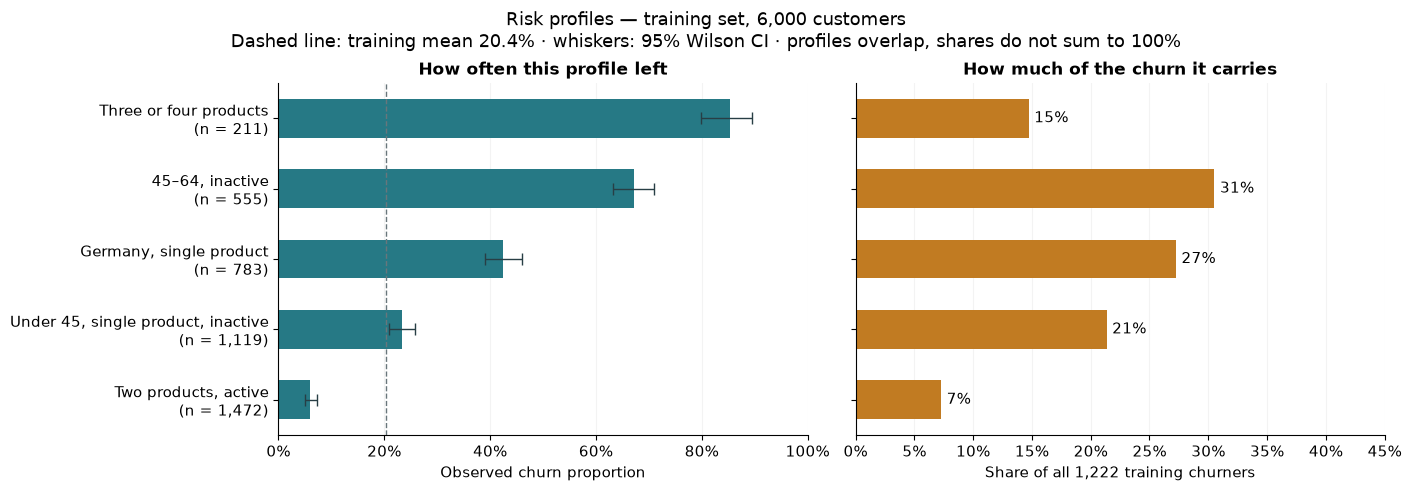

In [2]:
show = profiles.rename(columns={'profil':'Profile','n':'Training customers','departs':'Churners','proportion':'Churn proportion','part_des_departs':'Share of all departures','solde_moyen':'Mean balance (currency unknown)','ic95_bas':'95% CI lower','ic95_haut':'95% CI upper'})
display(show[['Profile','Training customers','Churners','Churn proportion','95% CI lower','95% CI upper','Share of all departures','Mean balance (currency unknown)']].style.format({'Training customers':'{:,}','Churn proportion':'{:.1%}','95% CI lower':'{:.1%}','95% CI upper':'{:.1%}','Share of all departures':'{:.1%}','Mean balance (currency unknown)':'{:,.0f}'}).hide(axis='index'))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), layout='constrained')
order = profiles.sort_values('proportion'); positions = np.arange(len(order))
axes[0].barh(positions, order.proportion, height=.55, color='#267985',
             xerr=[order.proportion - order.ic95_bas, order.ic95_haut - order.proportion],
             capsize=4, error_kw={'ecolor':'#283e45','elinewidth':1})
axes[0].axvline(eda['prevalence_train'], color='#69767b', linestyle='--', linewidth=1)
axes[0].set_yticks(positions, [f'{r.profil}\n(n = {r.n:,})' for r in order.itertuples()])
axes[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
axes[0].set(xlim=(0, 1), xlabel='Observed churn proportion')
axes[0].set_title('How often this profile left', fontsize=12, fontweight='bold')
bars = axes[1].barh(positions, order.part_des_departs, height=.55, color='#c17b22')
axes[1].bar_label(bars, labels=[f'{v:.0%}' for v in order.part_des_departs], padding=4)
axes[1].set_yticks(positions, [''] * len(order))
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
axes[1].set(xlim=(0, .45), xlabel=f"Share of all {eda['positive_train']:,} training churners")
axes[1].set_title('How much of the churn it carries', fontsize=12, fontweight='bold')
for ax in axes:
    ax.grid(axis='x', alpha=.15); ax.set_axisbelow(True)
fig.suptitle('Risk profiles — training set, 6,000 customers\nDashed line: training mean 20.4% · whiskers: 95% Wilson CI · profiles overlap, shares do not sum to 100%', fontsize=13)
plt.show()

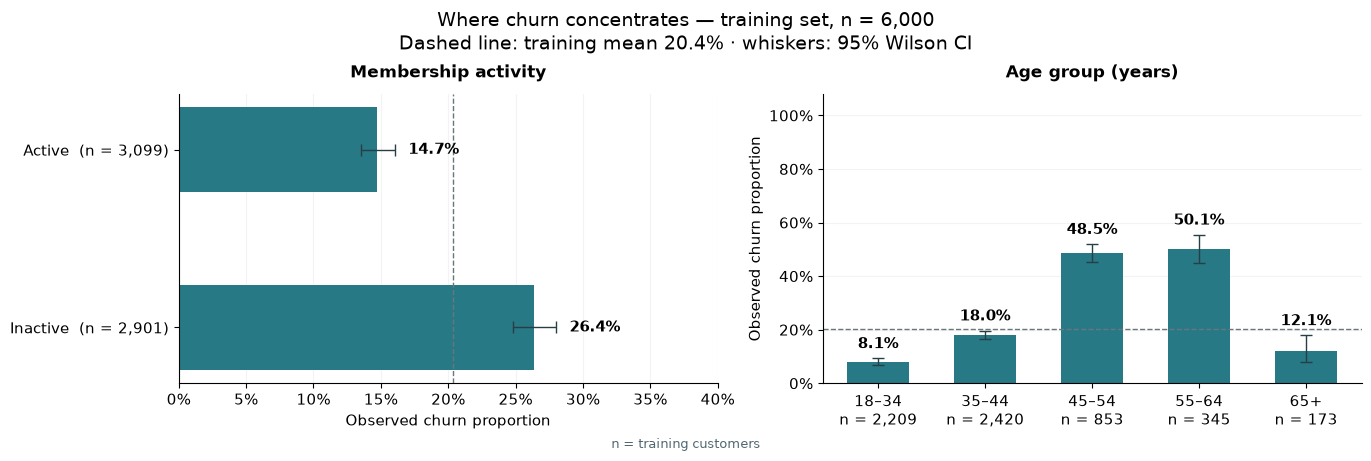

In [3]:
segment_rate_figure(pd.concat([segments, age_fine], ignore_index=True), ['IsActiveMember', 'AgeBandFine'],
                    eda['prevalence_train'], title='Where churn concentrates — training set, n = 6,000')
plt.show()

**Risk peaks at pre-retirement age, then falls.** Churn runs at 48.5% between 45 and 54 and 50.1% between 55 and 64, then drops to 12.1% among customers aged 65 and over (n = 173): retirees are the most stable group in the file. Reporting a single `55+` figure averages those two populations into one misleading number, which is why the band is split here.

**Inactivity is the clearest single lever to investigate**: 26.4% churn among inactive customers (n = 2,901) against 14.7% among active ones (n = 3,099). **Product count is not linear**: 27.3% with one product, 7.9% with two, 82.0% with three (n = 172) and all 39 customers with four. The three- and four-product groups churn massively but carry 15% of departures between them — a sales-quality question, not a campaign target.

**The zero-balance gap is largely a country effect.** Zero-balance customers churn 9.9 points less than others, but no German customer has a zero balance, and outside Germany the gap narrows to 4.5 points. It is composition, not an unexplained finding.

These are associations on undated records, unadjusted for one another and not adjusted for multiple comparisons. None of them identifies a cause, and none supports the claim that raising activity or selling a second product would prevent a departure.

## 4. The model: what it uses, and who it targets

Notebook 03 compared a prevalence-only baseline, a logistic regression and a random forest, each inside a pipeline fitting imputation, scaling and encoding on training folds only. The selection rule was fixed before the test was touched: pick the family on validation average precision, break ties on Brier, and keep sigmoid calibration only if it improves validation Brier while losing at most 0.01 of average precision. The random forest won on validation (average precision 0.707 against 0.634), calibration improved validation Brier from 0.1010 to 0.0996, and the calibrated forest was frozen along with the 20% quota, the targeting rules and the economic assumptions.

In [4]:
test_metrics = pd.DataFrame(result['metrics']).T
comparison = pd.DataFrame({
 'Model':[en(name) + (' — selected' if name == result['selected_model'] else '') for name in validation.index],
 'Validation AP':validation.average_precision.to_numpy(),
 'Validation Brier':validation.brier.to_numpy(),
 'Test ROC-AUC':test_metrics.loc[validation.index,'roc_auc'].to_numpy(),
 'Test AP':test_metrics.loc[validation.index,'average_precision'].to_numpy(),
 'Test Brier':test_metrics.loc[validation.index,'brier'].to_numpy(),
 'Churners reached at 400 contacts':test_metrics.loc[validation.index,'departs_contactes'].to_numpy(),
}).set_index('Model')
display(comparison.style.format({'Validation AP':'{:.3f}','Validation Brier':'{:.3f}','Test ROC-AUC':'{:.3f}','Test AP':'{:.3f}','Test Brier':'{:.3f}','Churners reached at 400 contacts':'{:.0f}'}))

,Validation AP,Validation Brier,Test ROC-AUC,Test AP,Test Brier,Churners reached at 400 contacts
Model,,,,,,
Naive baseline,0.204,0.162,0.500,0.203,0.162,79
Logistic regression,0.634,0.113,0.833,0.627,0.115,232
Random forest,0.707,0.101,0.857,0.685,0.105,248
Random forest (sigmoid) — selected,0.707,0.100,0.857,0.685,0.105,248


On the 2,000 test customers the selected model reaches ROC-AUC **0.857** (95% bootstrap interval 0.835–0.877), average precision **0.685** (0.634–0.727) and a Brier score of **0.105** (0.096–0.114), against a test prevalence of 20.35%. At the 400-contact quota, precision is 62% (95% interval 56.0%–67.2%), recall 60.9% (57.4%–65.1%) and lift 3.05 (2.87–3.25). Mean predicted probability is 20.6% against 20.35% observed, so probabilities are credible in aggregate. Calibration's benefit on test is marginal — Brier 0.10526 against 0.10534 uncalibrated — so it deserves credit for the validation improvement that motivated it, not for a test gain. The rejected logistic regression reaches 0.833 and 232 churners at the same capacity.

**What the score is made of.** Permutation importance on validation, measured as average precision lost when a feature is shuffled, puts almost everything on four variables. Credit score, tenure, card ownership and estimated salary contribute nothing measurable: four pieces of information would carry this score, which simplifies both industrialisation and the conversation with the business.

In [5]:
imp = pd.DataFrame(explanation['importance_permutation_ap'])
imp['variable'] = imp.variable.map({'Age':'Age','NumOfProducts':'Number of products','IsActiveMember':'Membership activity','Geography':'Country','Balance':'Balance','CreditScore':'Credit score','Tenure':'Tenure','HasCrCard':'Has credit card','EstimatedSalary':'Estimated salary'})
display(imp.rename(columns={'variable':'Feature','perte_ap_moyenne':'Average precision lost when shuffled','ecart_type':'Standard deviation (10 repeats)'}).style.format({'Average precision lost when shuffled':'{:.3f}','Standard deviation (10 repeats)':'{:.3f}'}).hide(axis='index'))
rows = {'part_partants':'Churn proportion','age_median':'Median age (years)','part_inactifs':'Inactive','part_allemagne':'Customers in Germany','part_un_produit':'Single product','part_trois_produits_ou_plus':'Three or four products','solde_moyen':'Mean balance (currency unknown)','part_femmes':'Women'}
who = pd.DataFrame({'Contacted (top 20%)':explanation['profil_cibles']['contactes'],'Not contacted':explanation['profil_cibles']['non_contactes'],'Churners the quota misses':explanation['angle_mort']['manques']})
who = who.loc[list(rows)].rename(index=rows)
display(who.style.format(lambda v: f'{v:,.0f}' if v > 3 else f'{v:.1%}'))

Feature,Average precision lost when shuffled,Standard deviation (10 repeats)
Age,0.265,0.013
Number of products,0.236,0.011
Membership activity,0.088,0.009
Country,0.052,0.006
Balance,0.024,0.009
Credit score,0.003,0.003
Tenure,0.000,0.001
Has credit card,0.000,0.002
Estimated salary,-0.001,0.002


,Contacted (top 20%),Not contacted,Churners the quota misses
Churn proportion,65.5%,9.1%,100.0%
Median age (years),47,36,39
Inactive,77.8%,41.1%,42.5%
Customers in Germany,48.8%,20.8%,28.1%
Single product,78.5%,45.9%,66.4%
Three or four products,14.0%,0.0%,0.0%
Mean balance (currency unknown),"88,803","74,152","95,483"
Women,50.5%,44.6%,61.6%


**Who the quota contacts.** The 400 customers it would reach are older (median 47 against 36), mostly inactive (78%), mostly single-product (79%), nearly half of them in Germany, and they hold larger balances than those left alone. That profile is recognisable to an advisor, which matters for adoption.

**Where it is blind.** On validation the quota misses **146 of 408 churners**, and they are the mirror image of the targeted profile: younger (median 39), only 42% inactive, no multi-product customers — and they hold **the largest mean balance of the three groups, 95,483**. The score has learned the older, inactive, single-product route to churn and misses a younger, wealthier one. That is a lead for a second model, not a defect to hide.

**One compliance point.** Gender is excluded from the model, yet women are slightly over-represented among contacted customers, 50.5% against 44.6% elsewhere. The disparity is small and the feature is absent, but it travels through correlated features: it belongs in a conversation with compliance before any campaign, not in a footnote.

These three views are computed on **validation rows after the single test opening** and are declared post hoc. They change no frozen choice.

## 5. From risk to a campaign decision

Two questions decide a campaign: **who** gets contacted, and **how many**.

On *who*, the frozen comparison at 400 contacts is honest but flattering: its business rule (`2 × inactive + 1 × age ≥ 45`) ignores product count and country, two of the four strongest signals of section 3. A manager who knows these customers would do better. The second table below adds a rule built from those findings — `3 × (products ≥ 3) + 2 × (aged 45–64) + inactive + Germany`, weights set by hand, no optimisation — on validation, declared post hoc.

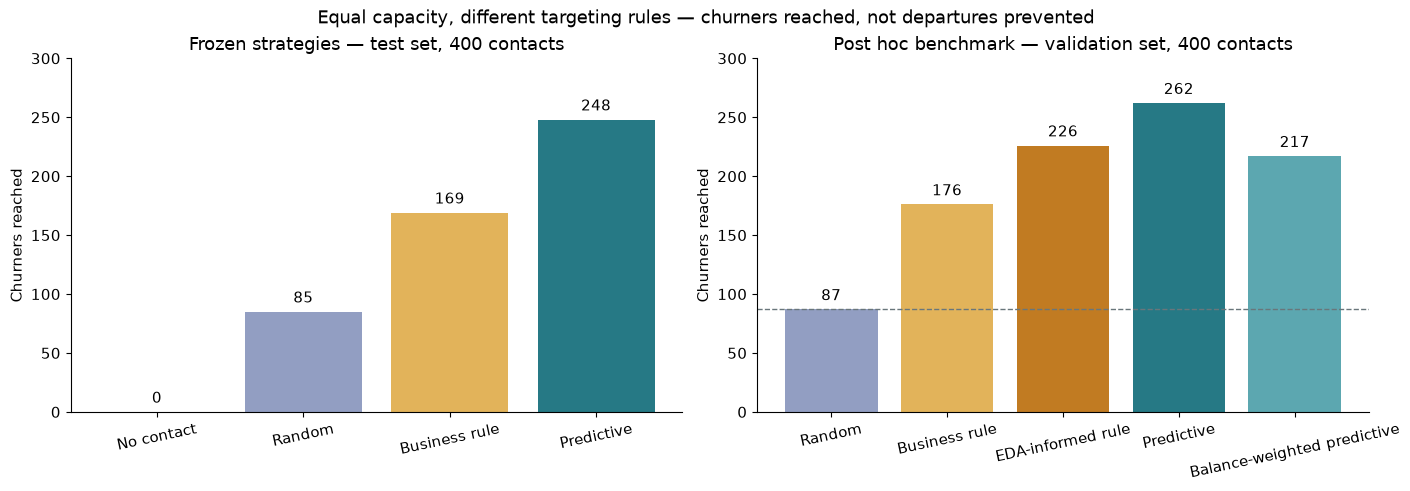

Rule (validation),Contacts,Churners reached,Precision,Recall,Lift,Mean balance contacted
Random,400,87,21.8%,21.3%,1.07,"79,379"
Business rule,400,176,44.0%,43.1%,2.16,"79,383"
EDA-informed rule,400,226,56.5%,55.4%,2.77,"90,954"
Predictive,400,262,65.5%,64.2%,3.21,"88,803"
Balance-weighted predictive,400,217,54.2%,53.2%,2.66,"126,418"


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), layout='constrained')
bars = axes[0].bar(strategies.strategie.map(en), strategies.departs_contactes, color=['#969696','#929ec2','#e2b35a','#267985'])
axes[0].bar_label(bars, padding=4)
axes[0].set(ylabel='Churners reached', title=f"Frozen strategies — test set, {int(strategies.contacts.max())} contacts", ylim=(0, 300))
axes[0].tick_params(axis='x', labelrotation=12)
bars = axes[1].bar(bench.strategie.map(en), bench.departs_contactes, color=['#929ec2','#e2b35a','#c17b22','#267985','#5ca7b0'])
axes[1].bar_label(bars, padding=4)
axes[1].axhline(float(bench.departs_contactes.iloc[0]), color='#69767b', linestyle='--', linewidth=1)
axes[1].set(ylabel='Churners reached', title='Post hoc benchmark — validation set, 400 contacts', ylim=(0, 300))
axes[1].tick_params(axis='x', labelrotation=12)
fig.suptitle('Equal capacity, different targeting rules — churners reached, not departures prevented', fontsize=13)
plt.show()
display(bench.assign(strategie=bench.strategie.map(en)).rename(columns={'strategie':'Rule (validation)','contacts':'Contacts','departs_contactes':'Churners reached','precision':'Precision','rappel':'Recall','lift':'Lift','solde_moyen_contactes':'Mean balance contacted'}).style.format({'Precision':'{:.1%}','Recall':'{:.1%}','Lift':'{:.2f}','Mean balance contacted':'{:,.0f}'}).hide(axis='index'))

Against a credible rule, the model's advance narrows from **+86 churners to +36** for the same 400 contacts — worth **US\$3,600 per campaign** under the reference assumptions. That is the real business question: does US\$3,600 a campaign cover building, deploying and maintaining a model, or is a well-built rule enough to start? Presented this way the number is defensible; presented against the deliberately simple rule it is not.

A balance-weighted variant of the score, ranking by score × balance as a proxy for exposure, was tested in the same frame: it contacts customers holding 126,418 on average instead of 88,803, but reaches 217 churners instead of 262. Exposure and risk are not aligned, and no margin data exists to arbitrate between them — the variant is reported, not recommended.

On *how many*, the 20% quota was always illustrative capacity, never an optimum. Under the frozen assumptions a contact is worth making while the customer's risk exceeds `c / (q × M)` = **10%**, and **960 of 2,000** validation customers clear that bar. The curve below draws the consequence.

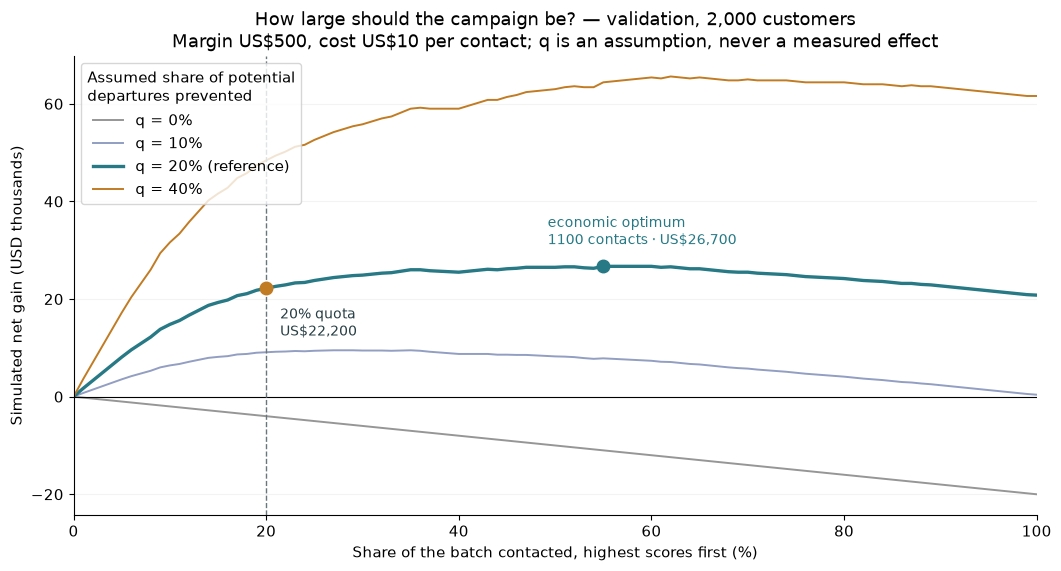

,Value
Reading of the reference scenario,
Simulated net gain per contact,US$52
Simulated gain per dollar spent,US$5.2
Gain interval implied by the precision bootstrap,"US$18,400 to US$22,900"
Contacts with nothing at stake (customers who stayed),"152 of 400 — US$1,216 of offers"
Retention rate needed to break even,3.2% of contacted churners


In [7]:
q_ref = economics['q']
fig, ax = plt.subplots(figsize=(10.5, 5.6), layout='constrained')
colors = {0:'#969696', .1:'#929ec2', .2:'#267985', .4:'#c17b22'}
for q, group in curve.groupby('q'):
    group = group.sort_values('contacts')
    ax.plot(group.part_contactee * 100, group.gain_net_scenario_usd / 1000, color=colors.get(q, '#283e45'),
            linewidth=2.4 if q == q_ref else 1.4, label=f'q = {q:.0%}' + (' (reference)' if q == q_ref else ''))
best = pd.DataFrame(ratios['optimum_capacite_validation']).set_index('q').loc[q_ref]
quota_gain = float(curve[(curve.q == q_ref) & (curve.contacts == 400)].gain_net_scenario_usd.iloc[0])
ax.axhline(0, color='black', linewidth=.8)
ax.axvline(20, color='#69767b', linestyle='--', linewidth=1)
ax.plot(20, quota_gain / 1000, 'o', color='#c17b22', markersize=9)
ax.annotate(f'20% quota\nUS${quota_gain:,.0f}', (20, quota_gain / 1000), textcoords='offset points', xytext=(10, -34), fontsize=10, color='#283e45')
ax.plot(100 * best.part_contactee, best.gain_net_scenario_usd / 1000, 'o', color='#267985', markersize=9)
ax.annotate(f'economic optimum\n{int(best.contacts)} contacts · US${best.gain_net_scenario_usd:,.0f}',
            (100 * best.part_contactee, best.gain_net_scenario_usd / 1000), textcoords='offset points', xytext=(-40, 16), fontsize=10, color='#267985')
ax.set(xlabel='Share of the batch contacted, highest scores first (%)', ylabel='Simulated net gain (USD thousands)', xlim=(0, 100),
       title='How large should the campaign be? — validation, 2,000 customers\nMargin US$500, cost US$10 per contact; q is an assumption, never a measured effect')
ax.legend(title='Assumed share of potential\ndepartures prevented')
ax.grid(axis='y', alpha=.15); ax.set_axisbelow(True)
plt.show()
display(pd.DataFrame([
 {'Reading of the reference scenario':'Simulated net gain per contact','Value':f"US${ratios['gain_net_par_contact_usd']:,.0f}"},
 {'Reading of the reference scenario':'Simulated gain per dollar spent','Value':f"US${ratios['gain_par_dollar_depense']:,.1f}"},
 {'Reading of the reference scenario':'Gain interval implied by the precision bootstrap','Value':f"US${ratios['intervalle_gain_usd']['bas']:,.0f} to US${ratios['intervalle_gain_usd']['haut']:,.0f}"},
 {'Reading of the reference scenario':'Contacts with nothing at stake (customers who stayed)','Value':f"{ratios['contacts_sans_enjeu']} of 400 — US${ratios['cout_offres_sans_enjeu_usd']:,.0f} of offers"},
 {'Reading of the reference scenario':'Retention rate needed to break even','Value':f"{ratios['q_point_mort_predictif']:.1%} of contacted churners"},
]).set_index('Reading of the reference scenario').style)

**The quota leaves money on the table, and that is not the model's main argument.** At the assumed 20% effect the optimum is **1,100 contacts for US\$26,700**, against US\$22,200 at the 400-contact quota — and contacting all 2,000 customers still returns US\$20,800. When the offer works well, targeting mostly buys **budget efficiency**: on this same validation curve, the 400-contact quota returns US\$5.6 of simulated gain per dollar spent against US\$1.0 for a blanket campaign — about five times as productive per dollar, for a total that is in fact slightly higher.

**Targeting becomes decisive when the offer is weak.** At q = 10% a blanket campaign returns US\$400 — barely above zero — while the 400 best scores still return US\$9,100. At q = 0 every campaign loses exactly its cost, US\$4,000, and no contact is the better choice. That is the honest shape of the risk: the campaign's value is entirely carried by an effect no one here has measured.

Two further costs belong in the decision. **152 of the 400 contacts go to customers who stayed**, US\$1,216 of offers with nothing at stake, and the precision interval alone puts the reference gain between US\$18,400 and US\$22,900 — before any uncertainty about margin, cost or effect. Fixed costs, implementation and opportunity costs are unspecified; this is not a complete investment case.

With a homogeneous effect and margin, equal cost and a fixed contact count, expected gain per customer is `p × q × M − c`, so ranking by risk also ranks expected gain. That equivalence breaks as soon as response, margin, cost or reachability varies by customer — exactly what the playbook below assumes, and exactly what a pilot has to measure.

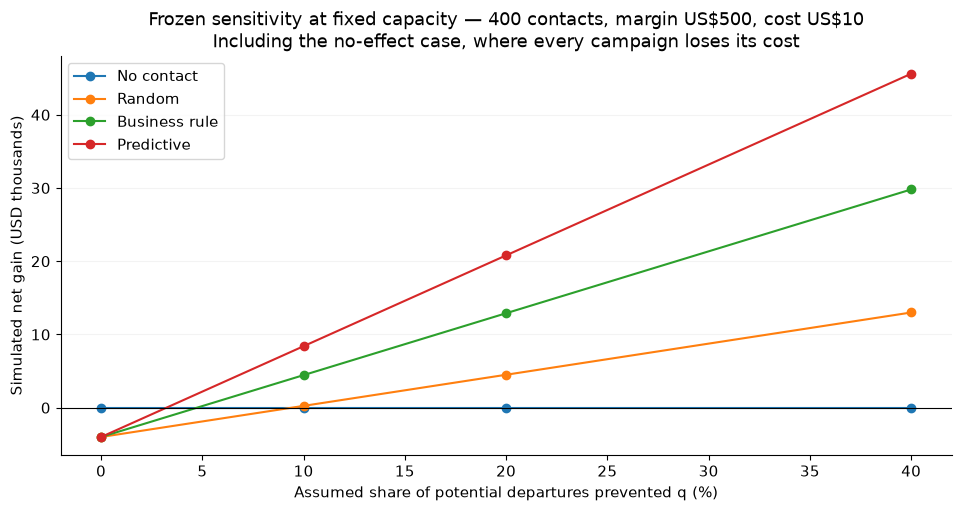

In [8]:
grid = scenarios[(scenarios.marge_eur == economics['margin_eur']) & (scenarios.cout_par_contact_eur == economics['cost_eur'])]
fig, ax = plt.subplots(figsize=(9.5, 5), layout='constrained')
for name in protocol['strategies']:
    group = grid[grid.strategie.eq(name)].sort_values('q')
    ax.plot(group.q * 100, group.gain_net_scenario_eur / 1000, 'o-', label=en(name))
ax.axhline(0, color='black', linewidth=.8)
ax.set(xlabel='Assumed share of potential departures prevented q (%)', ylabel='Simulated net gain (USD thousands)',
       title='Frozen sensitivity at fixed capacity — 400 contacts, margin US$500, cost US$10\nIncluding the no-effect case, where every campaign loses its cost')
ax.legend()
ax.grid(axis='y', alpha=.15); ax.set_axisbelow(True)
plt.show()

## 6. What a retention team should do differently

**1. Size the campaign from the economics, not from a quota.** The margin, cost and effect assumptions belong to retention and finance, not to the model: published as conventions, they can be challenged in committee and moved transparently. Once real costs and margins exist, set capacity where the curve peaks rather than at a round percentage, and re-derive the break-even risk — 10% under these assumptions — as the contact rule.

**2. Use the score where capacity is scarce, and compare it with a real rule.** Its measured advantage over a well-built business rule is +36 churners per 400 contacts, about US\$3,600 per campaign. Weigh that against the cost of deploying and maintaining a model. A rule may be enough to start; the score earns its place when capacity is tight, when the offer is weak, or once the younger high-balance churners it currently misses are also covered.

**3. Validate chronology and calibration before anything ships, then revalidate by cohort.** The absent out-of-time check is the main obstacle to prospective use. Establish which features are known before decision time t0, score a dated future cohort, and compare predicted probability with observed churn per cohort once follow-up is complete.

**And stop treating one uniform offer as a plan.** The frozen scenario gives everyone the same US\$8 offer, which is fine for a break-even calculation and inadequate as an action. The playbook pairs each profile with the hypothesis that would explain its churn and an action to **test**. The signals are measured; the hypotheses and the actions are not.

In [9]:
display(playbook[['profil','signal_train','hypothese','action_a_tester','canal_et_cout']].fillna('—').rename(columns={'profil':'Profile','signal_train':'Measured signal (training)','hypothese':'Hypothesis to verify','action_a_tester':'Action to test','canal_et_cout':'Channel and cost'}).style.hide(axis='index'))

Profile,Measured signal (training),Hypothesis to verify,Action to test,Channel and cost
"45–64, inactive","67% churn, 31% of departures, mean balance 84,418 (n=555)",Retirement and wealth-planning needs not covered,Appointment with a wealth advisor,"Advisor; high cost, justified by balances held"
"Germany, single product","43% churn, 27% of departures, mean balance 119,852 (n=783)",Offer or pricing less competitive in this market,"Diagnosis first: closure reasons and competitor pricing, then a local offer","Study, then targeted campaign"
Three or four products,"85% churn, 15% of departures, mean balance 77,318 (n=211)",Unsuitable equipment or pressured selling,Sales-quality audit; no additional commercial offer,"Quality and compliance, not marketing"
"Under 45, single product, inactive","23% churn, 21% of departures, mean balance 100,960 (n=1,119)","Secondary bank, weak relationship",Reactivation and a second useful product,Digital; low cost
"Two products, active","6% churn, 7% of departures, mean balance 51,762 (n=1,472)",Healthy relationship,Do not contact: every contact costs with nothing at stake,"No contact, by design"


Two consequences. **Cost and margin are not uniform across those rows.** An advisor appointment at US\$50 can be defended for a customer holding 119,852 in balance and not for a low-balance one, so `p × q × M − c` becomes a real decision tool only once c and M vary by segment. The single-cost scenario cannot express that: it is a limit of the scenario, not of the data.

**The move from one product to two is the strongest lead, and it is not proof.** Churn falls from 27.3% with one product to 7.9% with two, but engaged customers may simply be the ones who take a second product. Selling a product to prevent churn is precisely the hypothesis a pilot must test — and the three- and four-product groups, churning at 82% and 100%, are a warning against treating product sales as a retention lever.

## 7. Limits and next steps

**Retrospective population, no campaign data.** Nobody in the file was contacted, so uplift is unmeasurable here; the study ranks risk and claims no retention effectiveness.

**A conventional label.** The departure convention is inferred from a matching public example. Horizon, decision date and censoring are unknown, so no proportion is an annual rate and the twelve-month economic horizon is a planning assumption.

**No temporal validation.** The split is a stratified random partition of undated unique customers, and feature chronology is unverified; measured performance may overstate what a deployment would obtain.

**Assumed economics.** Margin, cost and effect are flat conventions, uniform across customers. The bootstrap intervals cover sampling in the test set conditional on the frozen policy, not uncertainty in the assumptions. The capacity curve, the benchmark rule and the score explanation are post hoc validation views, declared as such; no budget or policy was chosen on the test set.

**Thin segments, overlapping profiles, a known blind spot.** The four-product group holds 39 training customers and the three-product group 172; the five profiles overlap; and the quota misses 146 of 408 validation churners, concentrated among younger, higher-balance customers.

The next steps follow directly: confirm the file's provenance and publication rights; obtain the operational churn definition and horizon from the business; establish the features known before t0 and validate the frozen score on a dated future cohort; have retention and finance supply real offers, capacity, costs and net contribution per channel; raise the gender disparity among contacted customers with compliance; and only then run the pilot below.

### The pilot, in one page

| Question a decision-maker will ask | Answer |
|---|---|
| What is being tested? | Two actions against a control, on two score bands: the generic offer, and one playbook action matched to the profile |
| On whom? | Open accounts at t0, eligible, no concurrent campaign, scored by a temporally validated model. Top 20% of scores, plus a randomized slice in the 20–50% band |
| How many, how long? | Sample size fixed once the variance of net contribution is known; twelve months of follow-up with a three-month read on leading indicators |
| What does it cost? | Contacts × cost per channel, priced with finance; the US\$2 contact and US\$8 offer are placeholders |
| What is decided at the end? | Lower bound of the 95% interval for net contribution per assigned customer above US\$0 → deploy on the winning band and action. Otherwise → stop, or test another action. An effect confined to one band deploys only on that band |

Three departures from the protocol frozen in notebook 03, all registered **before randomization and outcome observation**: **several arms** instead of one offer, so the pilot learns which action works rather than only whether contacting works; **a randomized slice below the top 20%**, because the customers most at risk are not necessarily the most responsive and this is the only way to measure that; and **leading indicators at three months** — offer uptake, reactivation, complaints — so the organisation is not blind for a year. The primary outcome stays the difference in twelve-month net contribution per assigned customer, by intention to treat, with unreachable customers and offer refusers kept in the analysis. Notebook 04 holds the detailed protocol: strata, censoring, power and stopping rules.

**Decision:** fund this pilot after validating the data and the operating assumptions. Keep the score as a targeting candidate, and treat neither risk as uplift nor simulated dollars as realized value.

## Evidence and reproducibility

This publication notebook summarizes existing outputs and modifies none of them. It runs in a fresh kernel after the four analytical stages.

| Analytical source | Evidence summarized |
|---|---|
| `01-data-cleaning.ipynb` | Audit, documented label convention, exclusions and frozen split; `contract.json` |
| `02-data-analysis.ipynb` | Risk profiles, age bands, customer value and cross-tabulations; `segments_train.csv`, `age_bands_train.csv`, `profiles_train.csv`, `business_context_train.json`, `eda_summary.json` |
| `03-prediction.ipynb` | Validation choices, cached final evaluation, score explanation, blind spot, benchmark rules and gain curve; `validation_metrics.csv`, `frozen_protocol.json`, `test_evaluation.json`, `model_explanation.json`, `targeting_rules_validation.csv`, `gain_curve_validation.csv` |
| `04-business-insights.ipynb` | Decision framing, economic ratios, playbook and pilot; `business_scenarios.csv`, `economics_ratios.json`, `playbook.csv` |

The post hoc views added after the first business review — profiles, score explanation, benchmark rule and capacity curve — are computed on training and validation rows only, after the single test opening, and are recorded as a declared revision in `translation_provenance.json`. The sealed protocol, the cached test evaluation and the four original aggregate artifacts are unchanged.

Execute this report with `.venv/bin/python src/run_study.py summary`; export the single HTML report with `.venv/bin/python src/export_html.py`. The independent review and publication checks are recorded in `reports/review.md` and `reports/publication.md`.